# Exploratory analysis of the PaySim dataset

This notebook explores the Parquet data lake produced by `spark_jobs/ingest.py`
(run `python run_pipeline.py` first). All queries run on Spark.

**Dataset:** [PaySim](https://www.kaggle.com/datasets/ealaxi/paysim1) - 6.36M mobile money
transactions over 31 days, generated by a simulator calibrated on one month of real
transaction logs from a mobile money provider. Each row has a fraud label.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
os.chdir(os.path.abspath(".."))

import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from config import LAKE_DIR, RAW_CSV
from spark_jobs.common import get_spark

spark = get_spark("eda")
tx = spark.read.parquet(str(LAKE_DIR))
tx.createOrReplaceTempView("tx")
print(f"Raw CSV size: {RAW_CSV.stat().st_size / 1e6:.0f} MB")
print(f"Rows in lake: {tx.count():,}")

Raw CSV size: 494 MB


Rows in lake: 6,362,604


## Schema and sample rows

In [2]:
tx.printSchema()

root
 |-- step: integer (nullable = true)
 |-- amount: double (nullable = true)
 |-- name_orig: string (nullable = true)
 |-- old_balance_orig: double (nullable = true)
 |-- new_balance_orig: double (nullable = true)
 |-- name_dest: string (nullable = true)
 |-- old_balance_dest: double (nullable = true)
 |-- new_balance_dest: double (nullable = true)
 |-- is_fraud: integer (nullable = true)
 |-- is_flagged_fraud: integer (nullable = true)
 |-- day: integer (nullable = true)
 |-- hour_of_day: integer (nullable = true)
 |-- dest_is_merchant: integer (nullable = true)
 |-- error_balance_orig: double (nullable = true)
 |-- error_balance_dest: double (nullable = true)
 |-- orig_emptied: integer (nullable = true)
 |-- type: string (nullable = true)



In [3]:
tx.select("step", "type", "amount", "name_orig", "old_balance_orig", "new_balance_orig",
          "name_dest", "old_balance_dest", "new_balance_dest", "is_fraud").limit(5).toPandas()

,step,type,amount,name_orig,old_balance_orig,new_balance_orig,name_dest,old_balance_dest,new_balance_dest,is_fraud
0,1,CASH_IN,143236.26,C1862994526,0.00,143236.26,C1688019098,608932.17,97263.78,0
1,1,CASH_IN,228451.89,C1614133563,143236.26,371688.15,C2083562754,719678.38,1186556.81,0
2,1,CASH_IN,35902.49,C839771540,371688.15,407590.65,C2001112025,49003.30,0.00,0
3,1,CASH_IN,232953.64,C1037163664,407590.65,640544.28,C33524623,1172672.27,1517262.16,0
4,1,CASH_IN,65912.95,C180316302,640544.28,706457.23,C1330106945,104198.26,24044.18,0


## Parquet partitioning

The lake is partitioned by `type`, so a query on one type only reads that folder.
The physical plan shows the filter pushed down as a `PartitionFilters` entry.

In [4]:
for line in spark.sql("SELECT COUNT(*) FROM tx WHERE type = 'TRANSFER'")._jdf.queryExecution().executedPlan().toString().splitlines():
    if "PartitionFilters" in line:
        print(line.strip()[:220])

+- FileScan parquet [type#16] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/C:/Users/dhake/Desktop/bda/data/lake/transactions], PartitionFilters: [isnotnull(type#16), (type#1


In [5]:
sizes = {}
for d in sorted(LAKE_DIR.iterdir()):
    if d.is_dir():
        sizes[d.name] = sum(f.stat().st_size for f in d.glob("*.parquet")) / 1e6
print(f"CSV: {RAW_CSV.stat().st_size / 1e6:.0f} MB  ->  Parquet total: {sum(sizes.values()):.0f} MB")
sizes

CSV: 494 MB  ->  Parquet total: 315 MB


{'type=CASH_IN': 86.727073,
 'type=CASH_OUT': 110.193764,
 'type=DEBIT': 2.204661,
 'type=PAYMENT': 90.221332,
 'type=TRANSFER': 26.028194}

## Transaction types and fraud

In [6]:
by_type = spark.sql("""
    SELECT type, COUNT(*) AS n, SUM(is_fraud) AS fraud, ROUND(100 * AVG(is_fraud), 3) AS fraud_pct
    FROM tx GROUP BY type ORDER BY n DESC
""").toPandas()
by_type

,type,n,fraud,fraud_pct
0,CASH_OUT,2237484,4100,0.183
1,PAYMENT,2151495,0,0.000
2,CASH_IN,1399284,0,0.000
3,TRANSFER,532909,4097,0.769
4,DEBIT,41432,0,0.000


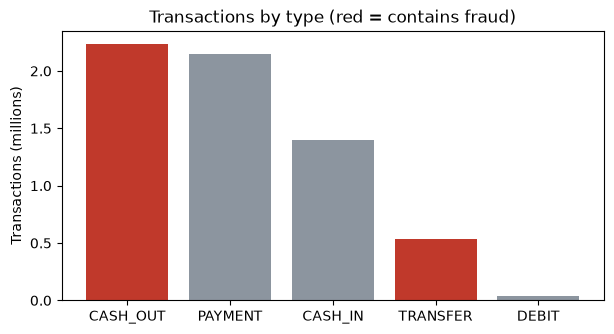

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["#c0392b" if f > 0 else "#8c959f" for f in by_type.fraud]
ax.bar(by_type.type, by_type.n / 1e6, color=colors)
ax.set_ylabel("Transactions (millions)")
ax.set_title("Transactions by type (red = contains fraud)")
plt.show()

Fraud only appears in **TRANSFER** and **CASH_OUT**. In the simulation, fraudsters take
over an account, transfer the balance to another account they control, then cash it out.
The near-equal counts (about 4,100 each) are consistent with that two-step pattern.

## Existing fraud rule

In [8]:
spark.sql("""
    SELECT is_flagged_fraud, is_fraud, COUNT(*) AS n
    FROM tx WHERE type = 'TRANSFER'
    GROUP BY is_flagged_fraud, is_fraud ORDER BY is_flagged_fraud, is_fraud
""").toPandas()

,is_flagged_fraud,is_fraud,n
0,0,0,528812
1,0,1,4081
2,1,1,16


`isFlaggedFraud` is the dataset's built-in rule (flag single transfers above 200,000 under
certain conditions). It is always right when it fires, but it only fires 16 times out of
8,197 frauds, so a better detector is clearly needed.

## Time of day

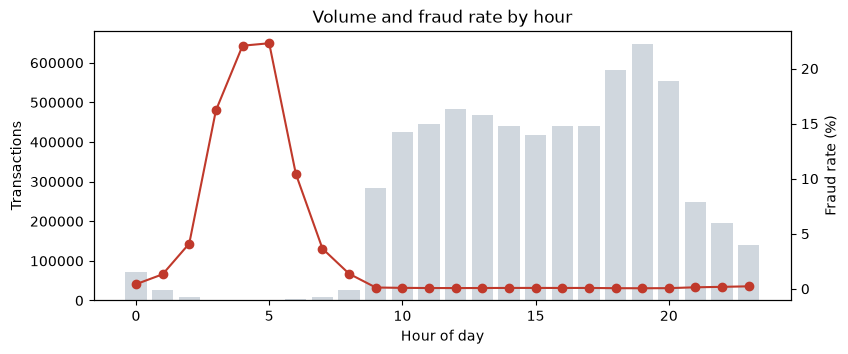

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
n,71587,27111,9017,2006,1241,1641,3419,8988,26915,283518,...,439653,416685,441612,439938,580509,647814,553727,247805,194553,141256
fraud,300,358,371,325,274,366,357,328,368,341,...,353,340,345,350,343,342,339,346,349,322


In [9]:
hourly = spark.sql("""
    SELECT hour_of_day, COUNT(*) AS n, SUM(is_fraud) AS fraud, 100 * AVG(is_fraud) AS fraud_pct
    FROM tx GROUP BY hour_of_day ORDER BY hour_of_day
""").toPandas()

fig, ax1 = plt.subplots(figsize=(9, 3.5))
ax1.bar(hourly.hour_of_day, hourly.n, color="#d0d7de", label="all transactions")
ax1.set_xlabel("Hour of day"); ax1.set_ylabel("Transactions")
ax2 = ax1.twinx()
ax2.plot(hourly.hour_of_day, hourly.fraud_pct, color="#c0392b", marker="o", label="fraud rate %")
ax2.set_ylabel("Fraud rate (%)")
ax1.set_title("Volume and fraud rate by hour")
plt.show()
hourly[["hour_of_day", "n", "fraud"]].T

Legitimate volume follows a daily cycle, but the number of frauds per hour is roughly
constant (about 270-370). Between 3:00 and 6:00 more than 15% of all transactions are
fraudulent, which makes `hour_of_day` a useful feature.

## Amounts

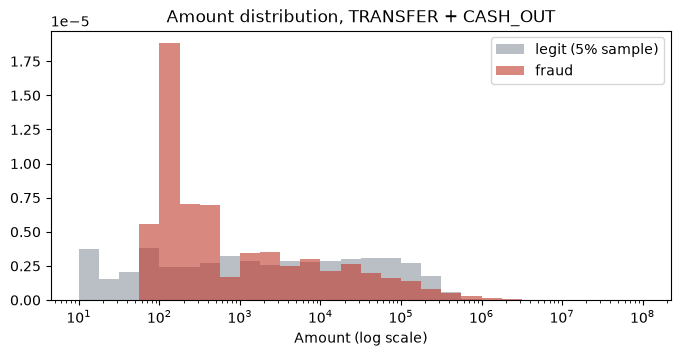

Fraud amounts exactly 10,000,000: 287


In [10]:
amounts = (tx.filter(F.col("type").isin("TRANSFER", "CASH_OUT"))
             .select("amount", "is_fraud").sample(fraction=0.05, seed=1).toPandas())
fraud_amounts = tx.filter("is_fraud = 1").select("amount").toPandas()

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = [10 ** (x / 4) for x in range(4, 33)]
ax.hist(amounts[amounts.is_fraud == 0].amount, bins=bins, alpha=0.6, density=True, label="legit (5% sample)", color="#8c959f")
ax.hist(fraud_amounts.amount, bins=bins, alpha=0.6, density=True, label="fraud", color="#c0392b")
ax.set_xscale("log"); ax.set_xlabel("Amount (log scale)"); ax.legend()
ax.set_title("Amount distribution, TRANSFER + CASH_OUT")
plt.show()
print("Fraud amounts exactly 10,000,000:", int((fraud_amounts.amount == 1e7).sum()))

Fraudulent amounts are larger on average, and no fraudulent transaction exceeds 10 million (287 are exactly 10,000,000), while legitimate amounts go up to 92 million.

## Balance inconsistencies

In [11]:
spark.sql("""
    SELECT is_fraud,
           ROUND(100 * AVG(orig_emptied), 1) AS pct_sender_emptied,
           ROUND(100 * AVG(CASE WHEN old_balance_dest = 0 AND new_balance_dest = 0 THEN 1 ELSE 0 END), 1) AS pct_receiver_stays_zero,
           ROUND(100 * AVG(CASE WHEN ABS(error_balance_orig) > 0.01 THEN 1 ELSE 0 END), 1) AS pct_sender_mismatch,
           ROUND(100 * AVG(CASE WHEN ABS(error_balance_dest) > 0.01 THEN 1 ELSE 0 END), 1) AS pct_receiver_mismatch
    FROM tx WHERE type IN ('TRANSFER', 'CASH_OUT') GROUP BY is_fraud
""").toPandas()

,is_fraud,pct_sender_emptied,pct_receiver_stays_zero,pct_sender_mismatch,pct_receiver_mismatch
0,1,97.7,49.7,0.5,56.6
1,0,42.7,0.1,90.6,22.6


`error_balance_orig = new_balance_orig + amount - old_balance_orig` (and the equivalent for
the receiver) measure how far the recorded balances are from what the amount implies.

- Almost every fraud empties the sender's account.
- In half of all frauds the receiver's balance is recorded as 0 before *and* after, even
  though money arrived. This almost never happens for legitimate transactions.

These derived columns become the strongest model features. They are also a quirk of how
the simulator records fraud, so real-world performance would be lower than what the model
achieves here.

## Repeat destinations

In [12]:
spark.sql("""
    SELECT name_dest, COUNT(*) AS frauds, ROUND(SUM(amount)) AS total
    FROM tx WHERE is_fraud = 1 GROUP BY name_dest HAVING COUNT(*) > 1
    ORDER BY total DESC LIMIT 10
""").toPandas()

,name_dest,frauds,total
0,C668046170,2,10160089.0
1,C1669818195,2,8848240.0
2,C1981613973,2,7265502.0
3,C1366192319,2,7061800.0
4,C964377943,2,6014862.0
5,C14138104,2,4597314.0
6,C1399829166,2,3540009.0
7,C643624257,2,3071717.0
8,C1013511446,2,2994972.0
9,C1601170327,2,2842695.0


Most frauds go to a different account each time, but 43 accounts received more than one
fraudulent transaction. In a real bank these would be candidates for mule-account review.

## Summary

| Finding | Used in |
|---|---|
| Fraud only in TRANSFER / CASH_OUT | model trained on these types only |
| Existing rule catches 0.2% of fraud | baseline for model comparison |
| Fraud rate peaks overnight | `hour_of_day` feature |
| Balance inconsistencies strongly separate fraud | `error_balance_*` features |
| Extreme class imbalance (0.3%) | class weights, precision/recall instead of accuracy |

In [13]:
spark.stop()